## 07 - Topic labeling and export

In 06 the model grouped the Italian reviews into 30 topics, each identified only by a number. Here every topic is read, given a short name and a category, or set aside when its reviews say nothing specific. The labeled reviews are then saved for the dashboard, after checking the results and how much the excluded reviews change the picture.

Input: `data/processed/trenord_reviews_topics.csv` and `data/processed/bertopic_model_trained/` (from 06), `data/processed/trenord_reviews_clean.csv` (only for the final privacy check)
Output: `trenord_reviews_labeled.csv`, `trenord_reviews_analysis.csv`, `top_reviews_per_topic.csv`, `bertopic_model_merged/`, three charts in `reports/figures/`

In [1]:
# --- IMPORTS ---
# Data and statistics
import numpy as np
import pandas as pd
from scipy.stats import t

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter

# Topic model
from bertopic import BERTopic
from bertopic.representation import MaximalMarginalRelevance

W1105 12:50:26.574000 31880 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


In [2]:
# --- LOAD DATA AND MODEL ---
# The reviews with their topic number, and the model, both saved by 06
italian_df = pd.read_csv("../data/processed/trenord_reviews_topics.csv")

# 06 trained the model on Italian reviews only, so the file must contain nothing else
assert (italian_df["language"] == "it").all(), "topics.csv contains non-Italian reviews"

# Only the name of the embedding model was saved in 06, so it is passed again here
topic_model = BERTopic.load(
    "../data/processed/bertopic_model_trained",
    embedding_model="paraphrase-multilingual-mpnet-base-v2"
)

print(f"Italian reviews loaded: {len(italian_df):,}")
print(f"Topics in the model   : {len(set(topic_model.topics_))}")

Loading weights: 100%|██████████| 199/199 [00:02<00:00, 81.20it/s]


Italian reviews loaded: 6,951
Topics in the model   : 30


In [3]:
# --- CHECK: FILE AND MODEL AGREE ---
# 06 saves topics.csv and the model together. If one of them was replaced later,
# some reviews would have a different topic in the file and in the model.
file_topics = italian_df["topic"].tolist()
model_topics = list(topic_model.topics_)

same_topics = file_topics == model_topics
print(f"Same topic for every review in file and model: {same_topics}")

assert same_topics, "topics.csv and the model disagree: rerun 06 so they are saved together"

Same topic for every review in file and model: True


In [4]:
# --- TOPIC OVERVIEW: THE EVIDENCE BEHIND THE LABELS ---
# One row per topic with what was looked at to give it a label: size, average rating,
# share of negative and positive reviews, share of very short reviews (the exclusion rule)
# and the top 5 keywords. Review texts are not shown, because notebook outputs are published.
rows = []
for topic_id in sorted(italian_df["topic"].unique()):
    topic_reviews = italian_df[italian_df["topic"] == topic_id]

    keywords = []
    for word, weight in topic_model.get_topic(topic_id)[:5]:
        keywords.append(word)

    # (condition).mean() gives the share of reviews for which the condition is true
    rows.append({
        "topic": topic_id,
        "reviews": len(topic_reviews),
        "avg rating": round(topic_reviews["rating"].mean(), 2),
        "1-2 stars (%)": round((topic_reviews["rating"] <= 2).mean() * 100, 1),
        "4-5 stars (%)": round((topic_reviews["rating"] >= 4).mean() * 100, 1),
        "5 words or fewer (%)": round((topic_reviews["word_count"] <= 5).mean() * 100, 1),
        "top keywords": ", ".join(keywords),
    })

topic_overview = pd.DataFrame(rows).set_index("topic")

# Show the keyword lists in full instead of cutting them
pd.set_option("display.max_colwidth", None)
topic_overview

,reviews,avg rating,1-2 stars (%),4-5 stars (%),5 words or fewer (%),top keywords
topic,,,,,,
0,1214,1.81,77.5,14.3,1.2,"treni, treno, ritardi, app, stazione"
1,1143,1.41,88.9,5.2,1.7,"biglietti, acquistare biglietti, app, acquisto, errore"
2,641,1.44,87.8,5.3,3.4,"pagamento, abbonamenti, rinnovare abbonamento, credito, carta credito"
3,499,1.43,88.2,5.8,51.9,"lenta, inutile, inaffidabile, difficile, incomprensibile"
4,515,1.54,83.1,8.0,9.3,"app, aggiornamento, telefono, android, problema"
5,219,1.45,88.6,3.7,3.7,"login, account, accesso, errore, mail"
6,185,1.75,80.5,11.4,11.9,"ritardi, ritardo, ritardi cancellazioni, arrivano ritardo, aggiornamento reale"
7,173,1.68,80.9,9.2,4.0,"stazioni, stazione, stazioni preferite, aggiornamento, reinstallato"
8,176,4.27,11.9,86.4,25.6,"ottima app, app comoda, app facile, app funziona, app veloce"


In [5]:
# --- LABEL MAP ---

EXCLUDE = "EXCLUDE"

TOPIC_LABELS = {
    # Delays and cancellations shown late, wrong or not at all (0, 6 and 29 share this theme)
    0:  ("Unreliable Train Status", "App Issue", ["treni", "ritardi"]),
    # Tickets that cannot be bought, errors at checkout
    1:  ("Ticket Purchase Failures", "App Issue", ["biglietti", "errore"]),
    # Subscription renewal and payment errors
    2:  ("Subscription Purchase Failures", "App Issue", ["pagamento", "abbonamenti"]),
    # Borderline: 52% of reviews are short, but it is the only topic about a slow, unclear app
    3:  ("Poor Usability", "App Issue", ["lenta", "difficile"]),
    # The app stops working, often after an update
    4:  ("App Crashes & Freezes", "App Issue", ["aggiornamento", "android"]),
    # Login and account problems
    5:  ("Login & Account Issues", "App Issue", ["login", "account"]),
    # Short reviews saying delays are not shown in real time
    6:  ("Unreliable Train Status", "App Issue", ["ritardi", "ritardi cancellazioni"]),
    # Favourite stations lost, station search not working
    7:  ("Station & Favorites Bugs", "App Issue", ["stazioni", "stazioni preferite"]),
    # The app is convenient and easy to use
    8:  ("Ease of Use", "Praise", ["app comoda", "app facile"]),
    # Excluded (73% short): generic praise; "utilissima" and "efficace" make it a borderline case
    9:  (EXCLUDE, None, ["ottima applicazione", "utilissima"]),
    # Excluded (99% short): one-word praise
    10: (EXCLUDE, None, ["ottima", "perfetta"]),
    # Short, but names specific qualities: easy, simple, intuitive
    11: ("Ease of Use", "Praise", ["facile", "intuitivo"]),
    # Buying tickets in the app is easy
    12: ("Easy Purchase & Payment", "Praise", ["biglietti", "facile"]),
    # QR code of the ticket missing or not read at the metro gates
    13: ("QR Code Failures", "App Issue", ["codice", "metro"]),
    # Excluded (90% short): generic praise of the service
    14: (EXCLUDE, None, ["ottimo", "complimenti"]),
    # Problems that started after an update
    15: ("App Crashes & Freezes", "App Issue", ["aggiornamento", "bug"]),
    # Excluded (64% short): "it works" without saying what
    16: (EXCLUDE, None, ["funziona funziona", "funzionante"]),
    # Paying for subscriptions in the app is fast
    17: ("Easy Purchase & Payment", "Praise", ["pagamento", "rapido"]),
    # Comparisons with earlier versions of the app
    18: ("Version Comparisons", "App Updates", ["migliorata", "migliorare"]),
    # About the trains and the company, not the app
    19: ("Rail Service Complaints", "Rail Service", ["servizio pessimo", "azienda"]),
    # Short, but names specific qualities: efficient, fast
    20: ("Ease of Use", "Praise", ["efficiente", "rapida"]),
    # Excluded (72% short): vague remarks ("does its job"), strikes, no clear theme
    21: (EXCLUDE, None, ["dovere", "sufficiente"]),
    # Registration problems, part of the same account process as topic 5
    22: ("Login & Account Issues", "App Issue", ["registrare", "profilo"]),
    # Excluded (78% short): "ottima app" and nothing else
    23: (EXCLUDE, None, ["ottima app", "buona app"]),
    # Short, but names specific qualities: easy and fast
    24: ("Ease of Use", "Praise", ["facile veloce", "semplice veloce"]),
    # Excluded (98% short): one-word negative verdicts
    25: (EXCLUDE, None, ["pessima pessima", "negativa"]),
    # Excluded (82% short): "it does not work" without saying what
    26: (EXCLUDE, None, ["funziona", "impossibile utilizzare"]),
    # Excluded (92% short): one-word negative verdicts
    27: (EXCLUDE, None, ["pessima pessima", "disastrosa"]),
    # Stations removed from the app or missing from its list
    28: ("Missing Stations", "App Issue", ["milano", "alcune stazioni"]),
    # Delays the app does not report
    29: ("Unreliable Train Status", "App Issue", ["ritardi", "app aggiornata"]),
}

In [6]:
# --- CHECK THE LABEL MAP ---
# Check 1: every topic of the model has exactly one entry in the map
model_topic_ids = sorted(set(topic_model.topics_))
assert sorted(TOPIC_LABELS) == model_topic_ids, "The map and the model do not have the same topics"

# Check 2: every topic still has its two keywords among its top 10 keywords.
# If one is missing, the model has changed since the labels were written.
missing_keywords = []
for topic_id, entry in TOPIC_LABELS.items():
    # entry is (label, category, keywords): the keywords are the third element
    anchors = entry[2]

    topic_words = []
    for word, weight in topic_model.get_topic(topic_id):
        topic_words.append(word)

    for anchor in anchors:
        if anchor not in topic_words:
            missing_keywords.append(f"topic {topic_id}: {anchor}")

print(f"Topics in the map : {len(TOPIC_LABELS)}")
print(f"Keywords not found: {len(missing_keywords)}")

assert len(missing_keywords) == 0, "The model has changed, the labels must be rebuilt: " + ", ".join(missing_keywords)

Topics in the map : 30
Keywords not found: 0


In [7]:
# --- APPLY THE LABELS ---
# Every review gets the label and the category of its topic.
label_by_topic = {}
category_by_topic = {}
for topic_id, entry in TOPIC_LABELS.items():
    label_by_topic[topic_id] = entry[0]
    category_by_topic[topic_id] = entry[1]

# map() replaces each topic number with its label or category
italian_df["topic_label"] = italian_df["topic"].map(label_by_topic)
italian_df["category"] = italian_df["topic"].map(category_by_topic)

# No review should be left without a label
assert italian_df["topic_label"].notna().all(), "Some reviews have no label"

kept_reviews = italian_df[italian_df["topic_label"] != EXCLUDE]
excluded_reviews = italian_df[italian_df["topic_label"] == EXCLUDE]

print(f"Labels, excluding EXCLUDE: {kept_reviews['topic_label'].nunique()}")
print(f"Reviews kept             : {len(kept_reviews):,}")
print(f"Reviews excluded         : {len(excluded_reviews):,}")
print(f"Share excluded           : {len(excluded_reviews) / len(italian_df) * 100:.1f}%")

Labels, excluding EXCLUDE: 13
Reviews kept             : 5,998
Reviews excluded         : 953
Share excluded           : 13.7%


In [8]:
# --- WHICH TOPICS TO MERGE ---
# Topics with the same label are merged. The list comes from the label map,
# so it cannot disagree with it. Excluded topics are left as they are.
topics_by_label = {}
for topic_id, entry in TOPIC_LABELS.items():
    label = entry[0]
    if label == EXCLUDE:
        continue
    if label not in topics_by_label:
        topics_by_label[label] = []
    topics_by_label[label].append(topic_id)

# Only labels with more than one topic need a merge
topics_to_merge = []
for label, topic_ids in topics_by_label.items():
    if len(topic_ids) > 1:
        topics_to_merge.append(topic_ids)
        print(f"{label}: topics {topic_ids}")

Unreliable Train Status: topics [0, 6, 29]
App Crashes & Freezes: topics [4, 15]
Login & Account Issues: topics [5, 22]
Ease of Use: topics [8, 11, 20, 24]
Easy Purchase & Payment: topics [12, 17]


In [9]:
# --- MERGE THE TOPICS ---
# merge_topics() needs the texts in the same order as the model's assignments,
# with empty texts replaced by a space, as in 06
texts = italian_df["text_clean"].tolist()
for i in range(len(texts)):
    is_valid = isinstance(texts[i], str) and len(texts[i].strip()) > 0
    if not is_valid:
        texts[i] = " "

# The saved model does not keep MMR, so it is set again with the same diversity as in 06
topic_model.representation_model = MaximalMarginalRelevance(diversity=0.3)
topic_model.merge_topics(texts, topics_to_merge)

# After a merge BERTopic renumbers all topics by size, so the new numbers go in their own column
italian_df["topic_merged"] = topic_model.topics_
print(f"Topics after the merge: {italian_df['topic_merged'].nunique()}")

Topics after the merge: 22


In [10]:
# --- CHECK THE MERGE ---
# Each merged topic must hold a single label
labels_per_merged_topic = italian_df.groupby("topic_merged")["topic_label"].nunique()
assert (labels_per_merged_topic == 1).all(), "A merged topic contains more than one label"

# Each kept label must be a single merged topic
kept_reviews = italian_df[italian_df["topic_label"] != EXCLUDE]
merged_topics_per_label = kept_reviews.groupby("topic_label")["topic_merged"].nunique()
assert (merged_topics_per_label == 1).all(), "A label is split across more than one merged topic"

print("Every merged topic holds one label, and every label is one merged topic")

Every merged topic holds one label, and every label is one merged topic


In [11]:
# --- FINAL TOPICS ---
# One row per label: size, share of the analysis set, average rating and its 95% confidence
# interval. The interval shows how precise each average is: topics with few reviews have
# wider intervals, so their averages are less certain. Reviews are treated as independent.
analysis_df = italian_df[italian_df["topic_label"] != EXCLUDE].copy()
n_analysis = len(analysis_df)

rows = []
for label in analysis_df["topic_label"].unique():
    topic_reviews = analysis_df[analysis_df["topic_label"] == label]
    ratings = topic_reviews["rating"]
    n = len(ratings)

    # Standard error: how much the average would change from one sample to another
    standard_error = ratings.std() / np.sqrt(n)
    # 95% margin from the t distribution, with n - 1 degrees of freedom
    margin = t.ppf(0.975, n - 1) * standard_error

    rows.append({
        "label": label,
        "category": topic_reviews["category"].iloc[0],
        "reviews": n,
        "share (%)": round(n / n_analysis * 100, 1),
        "avg rating": round(ratings.mean(), 2),
        "95% CI low": round(ratings.mean() - margin, 2),
        "95% CI high": round(ratings.mean() + margin, 2),
    })

final_topics = pd.DataFrame(rows).sort_values("reviews", ascending=False).set_index("label")
display(final_topics)

# Reviews per category
category_counts = analysis_df["category"].value_counts()
category_table = pd.DataFrame({
    "reviews": category_counts,
    "share (%)": (category_counts / n_analysis * 100).round(1),
})
category_table

,category,reviews,share (%),avg rating,95% CI low,95% CI high
label,,,,,,
Unreliable Train Status,App Issue,1501,25.0,1.78,1.72,1.84
Ticket Purchase Failures,App Issue,1143,19.1,1.41,1.36,1.46
App Crashes & Freezes,App Issue,655,10.9,1.61,1.53,1.69
Subscription Purchase Failures,App Issue,641,10.7,1.44,1.37,1.51
Poor Usability,App Issue,499,8.3,1.43,1.35,1.51
Ease of Use,Praise,463,7.7,4.54,4.45,4.62
Login & Account Issues,App Issue,289,4.8,1.40,1.31,1.49
Easy Purchase & Payment,Praise,277,4.6,3.98,3.82,4.14
Station & Favorites Bugs,App Issue,173,2.9,1.68,1.52,1.85


,reviews,share (%)
category,,
App Issue,5090,84.9
Praise,740,12.3
Rail Service,87,1.5
App Updates,81,1.4


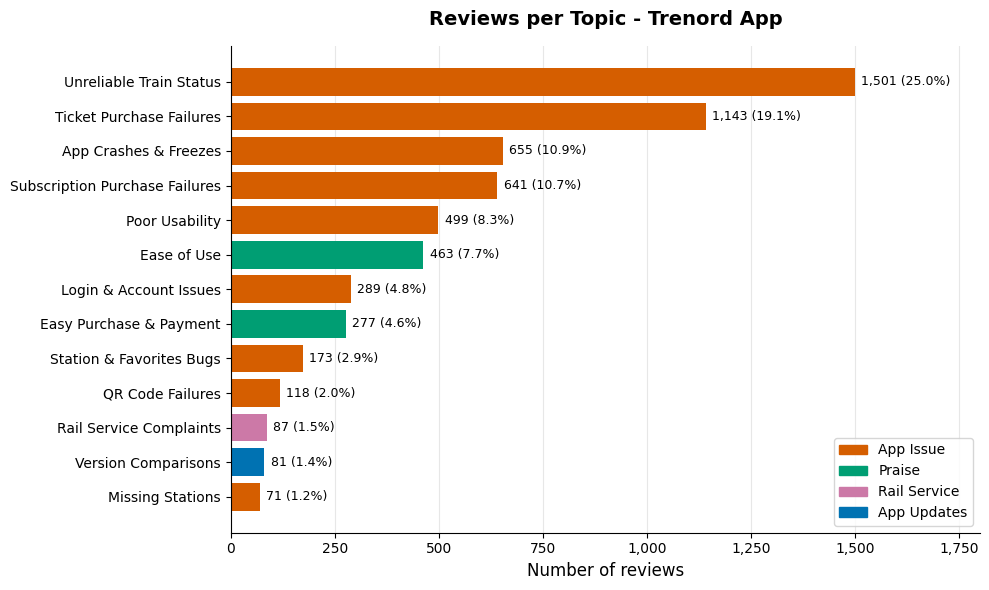

In [12]:
# --- CHART 1: REVIEWS PER TOPIC ---
# Horizontal bars, because topic names are long and read better on the left.
# The colour shows the category. Bars are drawn from the bottom, so the data is sorted
# from the smallest topic to the largest, which puts the largest at the top.

# Okabe-Ito colours: designed to stay distinct for readers with colour vision deficiency
CATEGORY_COLORS = {
    "App Issue": "#D55E00",
    "Praise": "#009E73",
    "Rail Service": "#CC79A7",
    "App Updates": "#0072B2",
}

chart_data = final_topics.sort_values("reviews")

bar_colors = []
for category in chart_data["category"]:
    bar_colors.append(CATEGORY_COLORS[category])

fig, ax = plt.subplots(figsize=(10, 6))

positions = range(len(chart_data))
ax.barh(positions, chart_data["reviews"], color=bar_colors)
ax.set_yticks(positions)
ax.set_yticklabels(chart_data.index)

# Number of reviews and share of the analysis set at the end of each bar
for i in range(len(chart_data)):
    reviews = chart_data["reviews"].iloc[i]
    share = chart_data["share (%)"].iloc[i]
    ax.text(reviews + 15, i, f"{reviews:,} ({share}%)", va="center", fontsize=9)

# One coloured square per category in the legend
legend_handles = []
for category, color in CATEGORY_COLORS.items():
    legend_handles.append(Patch(color=color, label=category))
ax.legend(handles=legend_handles, fontsize=10, loc="lower right")

ax.set_title("Reviews per Topic - Trenord App", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Number of reviews", fontsize=12)
ax.set_xlim(0, chart_data["reviews"].max() * 1.2)  # room for the labels at the end of the bars
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Light vertical grid behind the bars, to read the values more easily
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("../reports/figures/chart_reviews_per_topic.png", dpi=150)
plt.show()

Each bar is one of the 13 topics, with its number of reviews and its share of the 5,998 reviews in the analysis set. The colour is the category.

- App Issue dominates: 9 of the 13 topics and 84.9% of the reviews are about something in the app that does not work.
- The two largest topics alone hold 44% of the reviews, and both concern the core functions of the app: train status (Unreliable Train Status, 25.0%) and buying tickets (Ticket Purchase Failures, 19.1%).
- Praise covers two topics and 12.3% of the reviews, mostly about ease of use.
- Only 1.5% of the informative reviews complain about the trains or the company rather than the app.

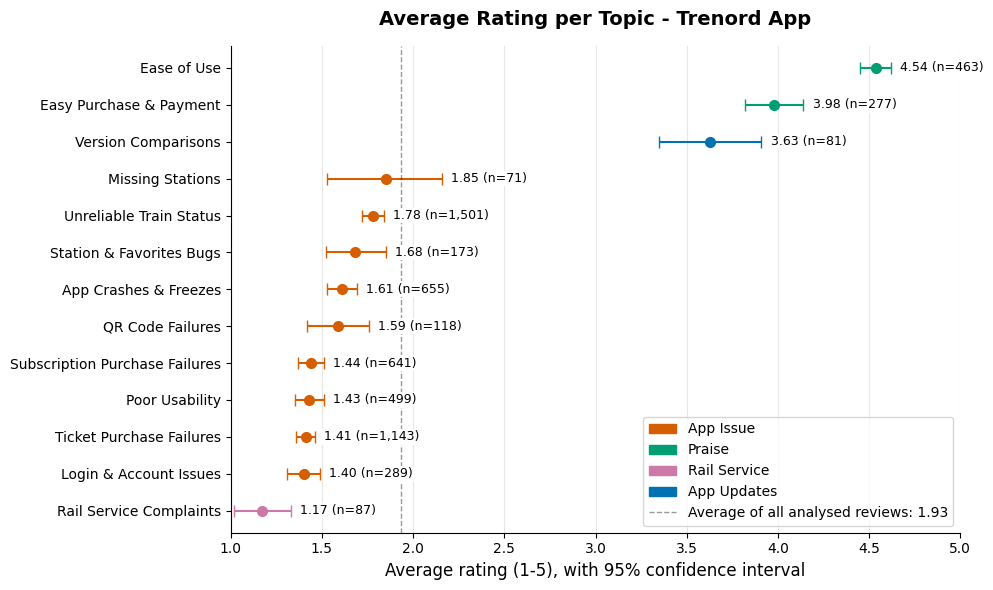

In [13]:
# --- CHART 2: AVERAGE RATING PER TOPIC ---
# A dot for each average instead of a bar: bars suggest a value that starts from zero,
# while ratings start from 1. The horizontal line through each dot is the 95% confidence
# interval from the final topics table: the shorter it is, the more precise the average.
# The axis covers the full 1-5 scale, so differences are not exaggerated.

# Sorted from the lowest average to the highest, which puts the highest at the top
chart_data = final_topics.sort_values("avg rating")

fig, ax = plt.subplots(figsize=(10, 6))

for i in range(len(chart_data)):
    avg = chart_data["avg rating"].iloc[i]
    ci_low = chart_data["95% CI low"].iloc[i]
    ci_high = chart_data["95% CI high"].iloc[i]
    n_reviews = chart_data["reviews"].iloc[i]
    color = CATEGORY_COLORS[chart_data["category"].iloc[i]]

    # xerr is the distance from the dot to each end of the interval: [[left], [right]]
    ax.errorbar(
        avg, i,
        xerr=[[avg - ci_low], [ci_high - avg]],
        fmt="o", color=color, markersize=7, capsize=4
    )
    # The average and the number of reviews, after the end of the interval.
    # The white background keeps the text readable where it crosses the reference line.
    ax.text(
        ci_high + 0.05, i, f"{avg:.2f} (n={n_reviews:,})",
        va="center", fontsize=9,
        bbox=dict(facecolor="white", edgecolor="none", pad=1)
    )

positions = range(len(chart_data))
ax.set_yticks(positions)
ax.set_yticklabels(chart_data.index)

# Reference line: the average of all reviews in the analysis set
analysis_avg = analysis_df["rating"].mean()
average_line = ax.axvline(
    x=analysis_avg,
    color="black", linestyle="--", linewidth=1, alpha=0.4,
    label=f"Average of all analysed reviews: {analysis_avg:.2f}"
)

# Legend: one square per category, plus the reference line
legend_handles = []
for category, color in CATEGORY_COLORS.items():
    legend_handles.append(Patch(color=color, label=category))
legend_handles.append(average_line)
ax.legend(handles=legend_handles, fontsize=10, loc="lower right")

ax.set_title("Average Rating per Topic - Trenord App", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Average rating (1-5), with 95% confidence interval", fontsize=12)
ax.set_xlim(1, 5)  # honest scale: the full rating range

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Light vertical grid behind the dots, as in chart 1
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("../reports/figures/chart_avg_rating_per_topic.png", dpi=150)
plt.show()

Each dot is the average rating of a topic, and the line through it is its 95% confidence interval: the range in which the true average plausibly lies. Short lines mean precise averages; long lines mean few reviews, as for Missing Stations (71). The dashed line is the average of all analysed reviews.

- All App Issue topics sit between 1.40 and 1.85 stars, below or close to the overall average. Their intervals overlap a lot, so the small differences between them, for example Ticket Purchase Failures (1.41) and Subscription Purchase Failures (1.44), should not be read as real differences.
- Rail Service Complaints has the lowest average (1.17): reviews about the trains and the company are even harsher than those about the app.
- The two Praise topics and Version Comparisons are far above all the others, with intervals that do not touch the App Issue ones.

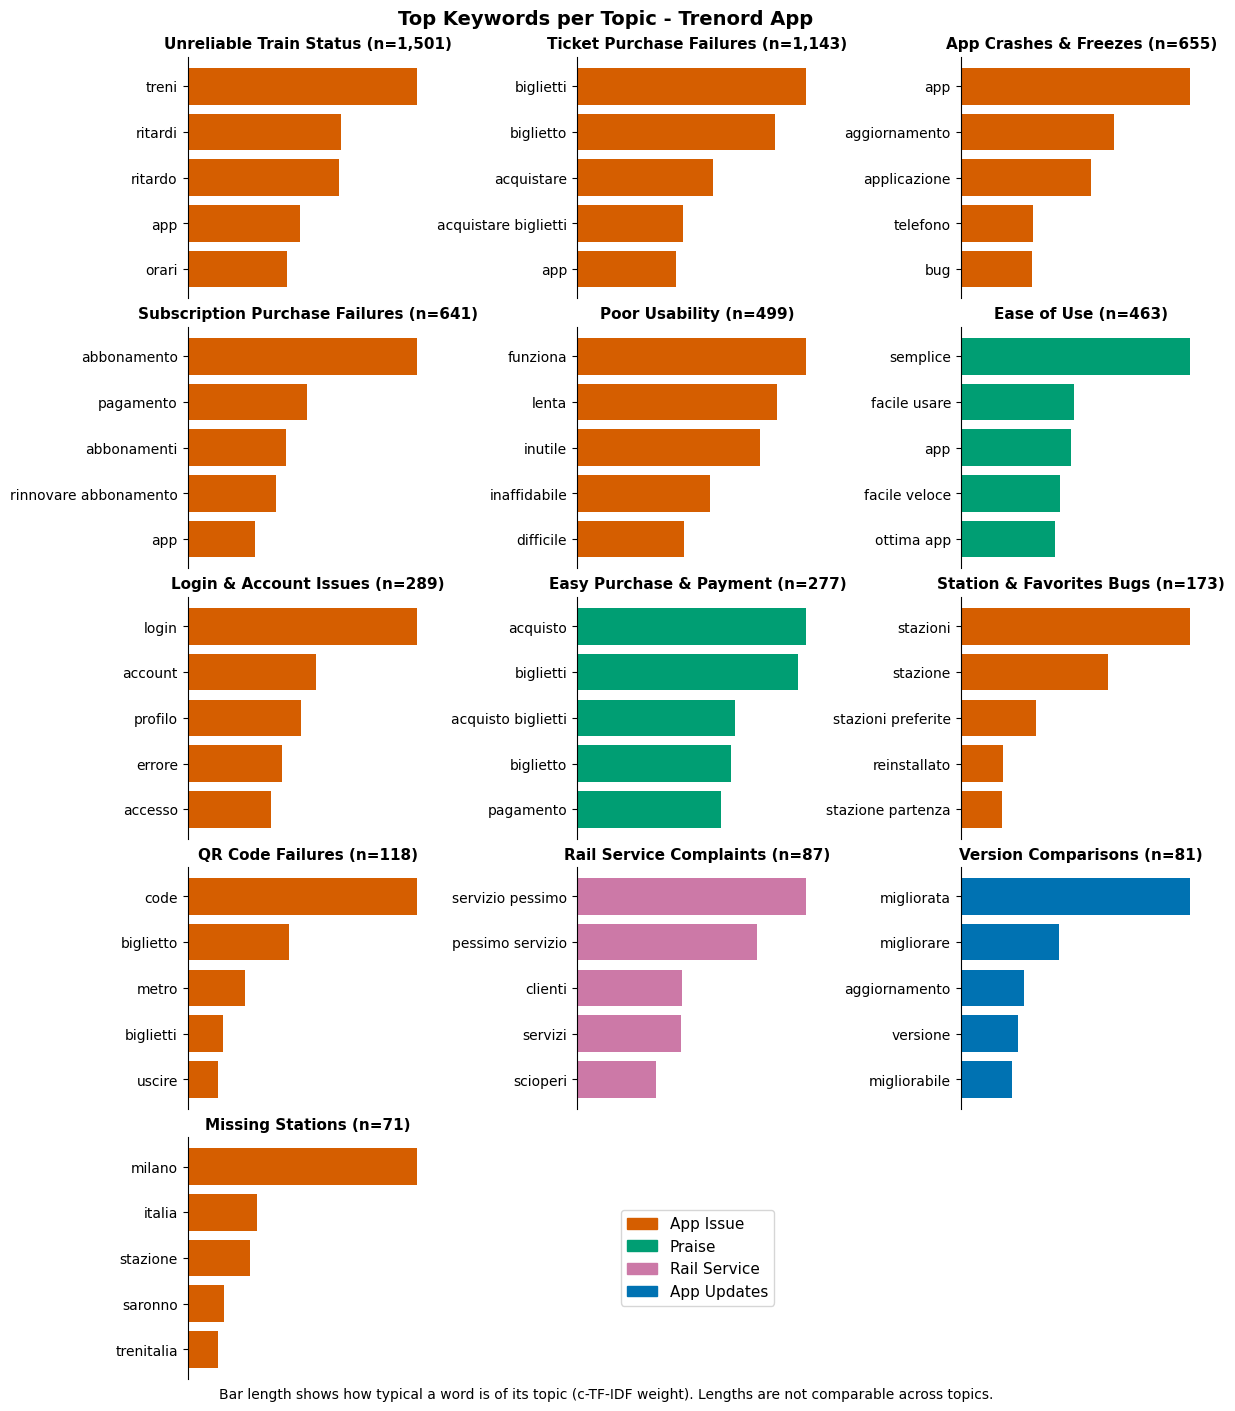

In [14]:
# --- CHART 3: KEYWORDS OF THE FINAL TOPICS ---
# The top 5 keywords of each of the 13 topics, taken from the merged model, so topics that
# share a label are described together. Bar length is the c-TF-IDF weight: how typical a
# word is of its own topic. Weights are not comparable across topics, so the axis has no
# numbers. Topics follow the order of chart 1, largest first.
N_WORDS = 5

# Merged topic number of each label (the merge check above showed that each label is one merged topic)
merged_id_by_label = {}
for label in final_topics.index:
    label_reviews = analysis_df[analysis_df["topic_label"] == label]
    merged_id_by_label[label] = label_reviews["topic_merged"].iloc[0]

# 3 columns x 5 rows = 15 panels for 13 topics. constrained layout keeps panels,
# titles and labels from overlapping.
fig, axes = plt.subplots(5, 3, figsize=(12, 14), layout="constrained")
axes = axes.flatten()  # one simple list of panels, easier to loop over

for i in range(len(final_topics)):
    label = final_topics.index[i]
    ax = axes[i]

    words = []
    weights = []
    for word, weight in topic_model.get_topic(merged_id_by_label[label])[:N_WORDS]:
        words.append(word)
        weights.append(weight)

    # Bars are drawn from the bottom: reversing puts the strongest word at the top
    words.reverse()
    weights.reverse()

    color = CATEGORY_COLORS[final_topics.loc[label, "category"]]
    ax.barh(words, weights, color=color)

    n_reviews = final_topics.loc[label, "reviews"]
    ax.set_title(f"{label} (n={n_reviews:,})", fontsize=11, fontweight="bold")

    # No numbers on the axis: lengths are compared only within a topic
    ax.set_xticks([])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_visible(False)

# The first empty panel holds the legend, the second is hidden
legend_panel = axes[len(final_topics)]
legend_panel.axis("off")
legend_handles = []
for category, color in CATEGORY_COLORS.items():
    legend_handles.append(Patch(color=color, label=category))
legend_panel.legend(handles=legend_handles, fontsize=11, loc="center")

for j in range(len(final_topics) + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Top Keywords per Topic - Trenord App", fontsize=14, fontweight="bold")
fig.supxlabel(
    "Bar length shows how typical a word is of its topic (c-TF-IDF weight). "
    "Lengths are not comparable across topics.",
    fontsize=10
)

plt.savefig("../reports/figures/chart_keywords_per_topic.png", dpi=150)
plt.show()

Each panel shows the 5 most typical words of a topic, after merging the topics that share a label. A longer bar means a word more typical of that topic. Lengths can be compared within a panel, not between panels.

- The keywords match the labels: "treni" and "ritardi" for Unreliable Train Status, "login" and "account" for Login & Account Issues, "milano" and names of other places for Missing Stations.
- Singular and plural forms appear as separate words ("biglietti" and "biglietto"). Keywords come from the cleaned text without lemmatization, which 06 keeps in natural form for the embeddings.
- The top word of Poor Usability is "funziona", most likely from "non funziona". It confirms that this topic is borderline, as noted in the label map.

In [15]:
# --- BIAS CHECK 1: ARE EXCLUDED REVIEWS RATED DIFFERENTLY? ---
# If the excluded reviews have a different rating profile, the analysis set no longer
# represents all Italian reviews, and the results must be read with this in mind.
excluded_df = italian_df[italian_df["topic_label"] == EXCLUDE]

print(f"Average rating, excluded    : {excluded_df['rating'].mean():.2f}")
print(f"Average rating, analysed    : {analysis_df['rating'].mean():.2f}")
print(f"Average rating, all Italian : {italian_df['rating'].mean():.2f}")

# Share of each rating in the two groups, to see where the difference is
rating_shares = pd.DataFrame({
    "excluded (%)": (excluded_df["rating"].value_counts(normalize=True).sort_index() * 100).round(1),
    "analysed (%)": (analysis_df["rating"].value_counts(normalize=True).sort_index() * 100).round(1),
})
rating_shares

Average rating, excluded    : 3.66
Average rating, analysed    : 1.93
Average rating, all Italian : 2.17


,excluded (%),analysed (%)
rating,,
1,27.5,62.3
2,2.0,12.0
3,2.8,6.9
4,12.5,7.8
5,55.2,11.0


In [16]:
# --- BIAS CHECK 2: IS THE EXCLUSION THE SAME IN EVERY YEAR? ---
# If the share of excluded reviews changes a lot from year to year, any comparison over time
# would mix a real change in the reviews with a change in what was excluded.
# 2026 is an incomplete year.
yearly_exclusion = pd.DataFrame({
    "reviews": italian_df["year"].value_counts().sort_index(),
    "excluded": excluded_df["year"].value_counts().sort_index(),
}).fillna(0).astype(int)

yearly_exclusion["excluded (%)"] = (yearly_exclusion["excluded"] / yearly_exclusion["reviews"] * 100).round(1)
yearly_exclusion

,reviews,excluded,excluded (%)
year,,,
2015,186,20,10.8
2016,154,26,16.9
2017,242,18,7.4
2018,452,34,7.5
2019,1005,187,18.6
2020,731,174,23.8
2021,670,116,17.3
2022,860,126,14.7
2023,929,86,9.3


The excluded reviews are not simply positive: they are short verdicts at both ends of the scale. 55.2% have 5 stars and 27.5% have 1 star, while the analysed reviews are mostly negative (62.3% with 1 star). Removing them makes the analysis set more negative than all Italian reviews: 1.93 against 2.17 stars on average. Topic results describe what users write about when they say something specific, not the overall satisfaction with the app.

The share of excluded reviews is not the same every year. It goes from 7.4% in 2017 to 23.8% in 2020, with a peak between 2019 and 2021. Rating trends computed on all reviews, as in notebook 04 and in the dashboard's Key Findings, are not affected. Trends of single topics over time use only the analysed reviews, so in 2019-2021 they rest on a smaller part of each year's reviews and should be read with this in mind.

In [17]:
# --- SAVE ALL OUTPUTS ---
# 1. trenord_reviews_labeled.csv : all Italian reviews with label and category, excluded ones included
# 2. trenord_reviews_analysis.csv: only the reviews of the 13 labeled topics (main dashboard file)
# 3. top_reviews_per_topic.csv   : the 5 most upvoted reviews of each topic (dashboard Deep Dive tab)
# 4. bertopic_model_merged       : the model after the merges
italian_df.to_csv("../data/processed/trenord_reviews_labeled.csv", index=False, encoding="utf-8-sig")
analysis_df.to_csv("../data/processed/trenord_reviews_analysis.csv", index=False, encoding="utf-8-sig")

# Top reviews: only reviews with at least one upvote, sorted from the most upvoted
upvoted = analysis_df[analysis_df["thumbs_up"] > 0]
upvoted = upvoted.sort_values("thumbs_up", ascending=False)

# head(5) keeps the first 5 rows of each topic, which are the 5 most upvoted
top_reviews = upvoted.groupby("topic_label").head(5)
top_reviews = top_reviews[["topic_label", "category", "rating", "thumbs_up", "date", "text"]]

# In the file, reviews of the same topic stay together, most upvoted first
top_reviews = top_reviews.sort_values(["topic_label", "thumbs_up"], ascending=[True, False])
top_reviews.to_csv("../data/processed/top_reviews_per_topic.csv", index=False, encoding="utf-8-sig")

# Same format as the model saved in 06: safetensors, word counts, embedding model name
topic_model.save(
    "../data/processed/bertopic_model_merged",
    serialization="safetensors",
    save_ctfidf=True,
    save_embedding_model="paraphrase-multilingual-mpnet-base-v2"
)

print(f"trenord_reviews_labeled.csv  : {len(italian_df):,} reviews")
print(f"trenord_reviews_analysis.csv : {len(analysis_df):,} reviews")
print(f"top_reviews_per_topic.csv    : {len(top_reviews)} reviews across {top_reviews['topic_label'].nunique()} topics")
print("bertopic_model_merged        : saved")

trenord_reviews_labeled.csv  : 6,951 reviews
trenord_reviews_analysis.csv : 5,998 reviews
top_reviews_per_topic.csv    : 65 reviews across 13 topics
bertopic_model_merged        : saved


In [18]:
# --- CHECK THE SAVED FILES: PRIVACY ---
# The files are read back from disk, because the dashboard and the public repository
# use the files, not the tables in memory.
labeled_out = pd.read_csv("../data/processed/trenord_reviews_labeled.csv")
analysis_out = pd.read_csv("../data/processed/trenord_reviews_analysis.csv")
top_out = pd.read_csv("../data/processed/top_reviews_per_topic.csv")
clean_df = pd.read_csv("../data/processed/trenord_reviews_clean.csv")

# 1. No author column in any file
no_author = ("author" not in labeled_out.columns
             and "author" not in analysis_out.columns
             and "author" not in top_out.columns)

# 2. Every review_id is pseudonymised: exactly 12 hexadecimal characters (made in 02)
ids_hashed = labeled_out["review_id"].str.fullmatch(r"[0-9a-f]{12}").all()

# 3. Developer replies are identical to those in clean.csv, which 02 checked against the
# original file. merge() works like a lookup on review_id.
replies = labeled_out[["review_id", "reply_text"]].merge(
    clean_df[["review_id", "reply_text"]], on="review_id", suffixes=("", "_clean")
)

# Every review must be found in clean.csv, otherwise the comparison would skip it
all_reviews_found = len(replies) == len(labeled_out)

# equals() treats two empty cells in the same position as equal
replies_identical = replies["reply_text"].equals(replies["reply_text_clean"])

print(f"No author column in any file    : {no_author}")
print(f"Every review_id is pseudonymised: {ids_hashed}")
print(f"Every review found in clean.csv : {all_reviews_found}")
print(f"Replies identical to clean.csv  : {replies_identical}")

assert no_author and ids_hashed and all_reviews_found and replies_identical, "A privacy check failed"

No author column in any file    : True
Every review_id is pseudonymised: True
Every review found in clean.csv : True
Replies identical to clean.csv  : True


In [19]:
# --- CHECK THE SAVED FILES: CONSISTENCY ---
n_labels = analysis_out["topic_label"].nunique()
categories_found = set(analysis_out["category"])
no_excluded = (analysis_out["topic_label"] != EXCLUDE).all()

print(f"Labels in the analysis file    : {n_labels}")
print(f"Categories in the analysis file: {sorted(categories_found)}")
print(f"No excluded reviews in it      : {no_excluded}")

# The four categories are taken from the colour dictionary, so they are not written twice
assert n_labels == 13, "The analysis file does not have 13 labels"
assert categories_found == set(CATEGORY_COLORS), "The analysis file does not have the 4 categories"
assert no_excluded, "The analysis file contains excluded reviews"

Labels in the analysis file    : 13
Categories in the analysis file: ['App Issue', 'App Updates', 'Praise', 'Rail Service']
No excluded reviews in it      : True


## Results

This project started from three questions about the Trenord app:

1. What do users complain about, and what do they appreciate?
2. How has their satisfaction changed over time?
3. How has Trenord responded?

This notebook answers the first one. The other two come from the ratings and the developer replies, analysed in notebook 04 and in the dashboard. They are summarised here so that the whole picture is in one place.

### What users complain about, and what they appreciate

Of the 30 topics found by the model, 21 describe something specific and were grouped under 13 labels; the other 9 were set aside because their reviews only give a verdict. The 13 labeled topics hold 5,998 reviews.

Most people who write something specific about the app do it because something does not work: 84.9% of these reviews describe an app issue. The two biggest problems concern exactly what the app is for, knowing where the trains are and buying a ticket:

- Unreliable Train Status (1,501 reviews, 25.0%): delays and cancellations shown late, wrong or not at all.
- Ticket Purchase Failures (1,143 reviews, 19.1%): tickets that cannot be bought, errors at checkout.
- Behind them come crashes and freezes (655), failed subscription purchases (641) and an app that is slow and hard to use (499).

All these topics have an average rating between 1.40 and 1.85 stars, and their confidence intervals overlap. Ranking them against each other would read too much into small differences: they are all rated badly.

What users appreciate is simple: an app that is easy and fast to use (Ease of Use, 463 reviews, 4.54 stars) and a purchase that goes through smoothly (Easy Purchase & Payment, 277 reviews, 3.98 stars). Together they are 12.3% of the reviews. Version Comparisons (81 reviews, 3.63 stars) shows that some users notice when an update makes the app better. Only 1.5% of the reviews are really about the trains and the company rather than the app, and they are the harshest of all (1.17 stars).

No topic is about requests for new features. Users describe what is broken much more than what they would like to have.

### How satisfaction has changed over time

The average rating of the Italian reviews fell from 3.54 stars in 2015 to 1.52 in 2025, and the sharpest recent drop came between 2022 and 2023. These values are for the Italian reviews and come from the dashboard. Notebook 04 shows the same trend for all languages, from 3.56 to 1.57.

### How Trenord has responded

Until 2020 Trenord replied to between 83% and 100% of the reviews every year. In 2021 the share fell to 32%, and since 2022 it has stayed below 4% (1.7% in 2025). These values are for the Italian reviews and come from the dashboard. Notebook 04 shows the same trend for all languages, from 32.5% in 2021 to 1.6% in 2025. The collapse of the replies and the fall of the ratings happen in the same years, but this analysis cannot say whether one caused the other.

### What to keep in mind

- The 953 excluded reviews (13.7%) are short verdicts at both ends of the scale: 55.2% have 5 stars and 27.5% have 1 star. Without them the analysed reviews are more negative than all Italian reviews (1.93 against 2.17 stars), so the topics describe what users say when they say something specific, not overall satisfaction.
- The share of excluded reviews changes from year to year, from 7.4% in 2017 to 23.8% in 2020. Trends of single topics over time need care; overall rating trends use all reviews and are not affected.
- The labels and the exclusion rule are judgements made by one person, and their reliability has not been measured on a sample of reviews.
- The reviews are the ones the Play Store makes available, about 43% of the app's ratings, collected newest first. Each review belongs to one topic only, even when it mentions several problems.
- The published files were checked: they contain no author names, every review id is pseudonymised and the developer replies are unchanged.